# 07 · Gradient Descent and Optimizers

**Learning objectives**
1. Derive the gradient descent update and the condition for convergence on $f(w)=w^2$.
2. Compare SGD, momentum, RMSProp and Adam on the same problem.
3. Recognize local minima and saddle points.

Modules: `src/optimizers.py`, `tests/test_optimizers.py`.

## 1. Gradient descent on $f(w) = w^2$

The gradient is $f'(w)=2w$. The update is

$$w_{t+1} = w_t - \eta\cdot 2w_t = (1-2\eta)\,w_t$$

So $|w_t| = |1-2\eta|^t |w_0|$, which converges if and only if $0<\eta<1$.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

def run_gd(w0, lr, steps):
    w = w0
    out = [w]
    for _ in range(steps):
        w = w - lr * 2 * w
        out.append(w)
    return np.array(out)

for lr in [0.1, 0.5, 1.1]:
    print(f"lr={lr}: first 4 values {np.round(run_gd(1.0, lr, 3), 4)}")

lr=0.1: first 4 values [1.    0.8   0.64  0.512]
lr=0.5: first 4 values [1. 0. 0. 0.]
lr=1.1: first 4 values [ 1.    -1.2    1.44  -1.728]


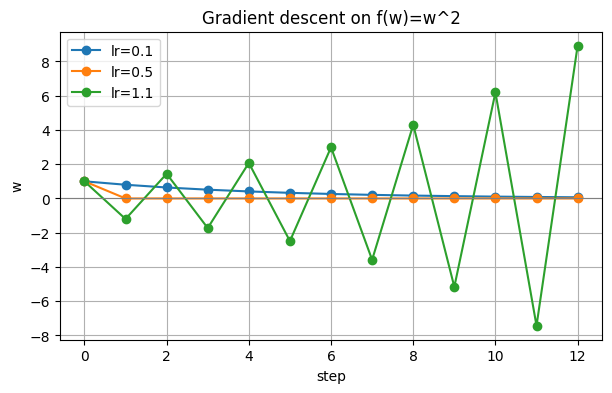

In [2]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

fig, ax = plt.subplots(figsize=(7, 4))
for lr in [0.1, 0.5, 1.1]:
    ax.plot(run_gd(1.0, lr, 12), marker="o", label=f"lr={lr}")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("step"); ax.set_ylabel("w"); ax.set_title("Gradient descent on f(w)=w^2")
ax.grid(True); ax.legend(); plt.show()

## 2. Optimizers compared

Same start $w_0=1$, learning rate $0.1$, three steps. The update rules live in `src/optimizers.py`.

In [3]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

from optimizers import sgd_step, momentum_step, rmsprop_step, adam_step

g = lambda w: 2 * w
w = np.array([1.0])
print("SGD:")
for _ in range(3):
    w = sgd_step(w, g(w), lr=0.1); print("  w =", round(float(w[0]), 4))

w = np.array([1.0]); v = np.array([0.0])
print("Momentum (beta=0.9):")
for _ in range(3):
    w, v = momentum_step(w, g(w), v, lr=0.1, beta=0.9); print("  w =", round(float(w[0]), 4), " v =", round(float(v[0]), 4))

w = np.array([1.0]); s = np.array([0.0])
print("RMSProp (rho=0.9):")
for _ in range(3):
    w, s = rmsprop_step(w, g(w), s, lr=0.1, rho=0.9); print("  w =", round(float(w[0]), 4))

w = np.array([1.0]); m = np.array([0.0]); v = np.array([0.0])
print("Adam (beta1=0.9, beta2=0.999):")
for t in range(1, 4):
    w, m, v = adam_step(w, g(w), m, v, t=t, lr=0.1); print("  w =", round(float(w[0]), 4))

SGD:
  w = 0.8
  w = 0.64
  w = 0.512
Momentum (beta=0.9):
  w = 0.8  v = 2.0
  w = 0.46  v = 3.4
  w = 0.062  v = 3.98
RMSProp (rho=0.9):
  w = 0.6838
  w = 0.4989
  w = 0.3692
Adam (beta1=0.9, beta2=0.999):
  w = 0.9
  w = 0.8004
  w = 0.7016


## 3. Local minima and saddle points

For a non-convex function, the start decides which minimum gradient descent reaches. The first example has a local and a global minimum.

start +1.5 -> w=+0.9601, f=-0.7059
start +0.5 -> w=+0.9601, f=-0.7059
start -0.5 -> w=-1.0356, f=-1.3054
start -1.5 -> w=-1.0356, f=-1.3054


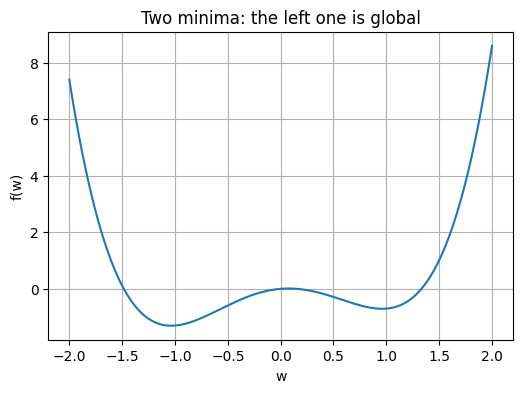

In [4]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

F = lambda w: w**4 - 2 * w**2 + 0.3 * w
G = lambda w: 4 * w**3 - 4 * w + 0.3

def run_to_end(w, lr=0.05, steps=300):
    for _ in range(steps):
        w = w - lr * G(w)
    return w

for w0 in [1.5, 0.5, -0.5, -1.5]:
    wf = run_to_end(w0)
    print(f"start {w0:+.1f} -> w={wf:+.4f}, f={F(wf):+.4f}")

xs = np.linspace(-2, 2, 400)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(xs, F(xs)); ax.grid(True); ax.set_xlabel("w"); ax.set_ylabel("f(w)")
ax.set_title("Two minima: the left one is global")
plt.show()

**Saddle point.** For $f(x,y)=x^2-y^2$, the origin has zero gradient but is not a minimum. Starting exactly on the $x$-axis, gradient descent converges to the saddle. A tiny $y$ component grows and the algorithm leaves it.

In [5]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

x, y = 0.5, 0.0
for _ in range(50):
    x, y = x - 0.1 * 2 * x, y - 0.1 * (-2 * y)
print("from (0.5, 0.0):", round(x, 6), round(y, 6))
x, y = 0.5, 1e-3
for _ in range(60):
    x, y = x - 0.1 * 2 * x, y - 0.1 * (-2 * y)
print("from (0.5, 1e-3) after 60 steps: y =", round(y, 3))

from (0.5, 0.0): 7e-06 0.0
from (0.5, 1e-3) after 60 steps: y = 56.348


## 4. Interpretation

- The learning rate must be below a limit set by the curvature. Too large diverges.
- Momentum accumulates gradients; RMSProp scales each step by recent gradient size; Adam combines both with bias correction.
- Optimizers change the path, not the minimum they are aiming for. Their default settings are a starting point, not a guarantee.

## 5. Exercises

1. For $w_0=2$ and $\eta=0.3$, predict $w_1$ and whether the sequence converges. Then check.
2. For momentum with $\beta=0.9$ and constant gradient $1$, compute $v_1$ and $v_2$ by hand.
3. Change $w_0$ to $0.9$ in the two-minimum example. Which minimum does gradient descent reach?